# Reinforcement Learning zur Insulinregelung bei Typ-1-Diabetes

**Simulator:** simglucose (UVA/Padova, 2008)

Dieses Notebook begleitet die Projektarbeit. Es zeigt der Reihe nach

1. das physiologische Modell als Differentialgleichungssystem,
2. die Wahrnehmungslücke zwischen wahrer und messbarer Glukose,
3. die klinische Referenztherapie,
4. die beiden Beobachtungsräume des Agenten,
5. die Ergebnisse und
6. die Sensitivitätsanalyse der Modellparameter.

Alle Zahlen stammen aus den protokollierten Laufdateien unter `runs/`.

## 0. Vorbereitung

Die Module liegen in `src/`. Der Simulator wird nicht über seine mitgelieferte
Gym-Umgebung angesprochen, sondern direkt über den ODE-Kern (Begründung in
`src/t1d_env.py`).

In [1]:
import sys, os, json, warnings, logging
sys.path.insert(0, os.path.abspath("../src"))
warnings.filterwarnings("ignore"); logging.disable(logging.CRITICAL)

import numpy as np
import matplotlib.pyplot as plt
from t1d_env import T1DEnv, MAX_MULT
from metrics import glycemic_metrics, summarize, TARGETS

plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.25})
print("bereit")

bereit


## 1. Das Modell: 13 gekoppelte Differentialgleichungen

Das UVA/Padova-Modell beschreibt Glukose- und Insulinkinetik eines
Typ-1-Diabetikers. Es gehört zur selben Klasse wie das Räuber-Beute-Modell und
das Noble-Modell des EKG aus der Vorlesung, ist nur größer. Gelöst wird es mit
`scipy.integrate.ode` (Verfahren `dopri5`) in Minutenschritten.

| Zustand | Bedeutung |
|---|---|
| `x[0]`, `x[1]` | Glukose im Magen (fest, flüssig) |
| `x[2]` | Glukose im Darm |
| `x[3]` | **Plasmaglukose** |
| `x[4]` | Gewebeglukose |
| `x[5]` bis `x[9]` | Insulinkinetik und Insulinwirkung |
| `x[10]`, `x[11]` | subkutanes Insulin |
| `x[12]` | **subkutane Glukose** (was der Sensor misst) |

In [2]:
env = T1DEnv(patient_name="adult#001", obs_mode="privileged", days=1)
print(f"Patient adult#001")
print(f"  stationäre Basalrate : {env.basal_ss:.5f} U/min")
print(f"  Zustandsdimension     : 13")
print(f"  Abtastzeit            : 3 min  ({env.max_steps} Schritte je Tag)")

Patient adult#001
  stationäre Basalrate : 0.02112 U/min
  Zustandsdimension     : 13
  Abtastzeit            : 3 min  (480 Schritte je Tag)


## 2. Die Wahrnehmungslücke

Der entscheidende Punkt der Arbeit steckt bereits im Modell. Der Sensor misst
nicht die Plasmaglukose `x[3]`, sondern die subkutane Glukose `x[12]`, und diese
folgt der Plasmaglukose nur verzögert:

$$\frac{dx_{12}}{dt} = k_{sc}\,(x_3 - x_{12})$$

Darauf addiert der Sensor korreliertes Rauschen (AR(1)-Prozess, alle 15 Minuten
erzeugt, kubisch interpoliert, durch eine Johnson-SU-Transformation geschickt).
Wir messen beides.

Gemessen wird über **20 Episoden**, nicht über eine. Das Rauschen ist eine
Zufallsgröße: über die Einzeltage schwankt seine Standardabweichung zwischen
6,9 und 16,4 mg/dL. Ein einzelner Tag würde je nach Ziehung einen zu guten oder
zu schlechten Sensor zeigen.

Verzögerung subkutan gegen Plasma : 4 Schritte = 12 min  (in 20 von 20 Episoden)
Sensorrauschen (CGM - subkutan) SD : 11.04 +/- 2.32 mg/dL
Mittlerer Betragsfehler CGM/Plasma : 10.01 +/- 1.64 mg/dL


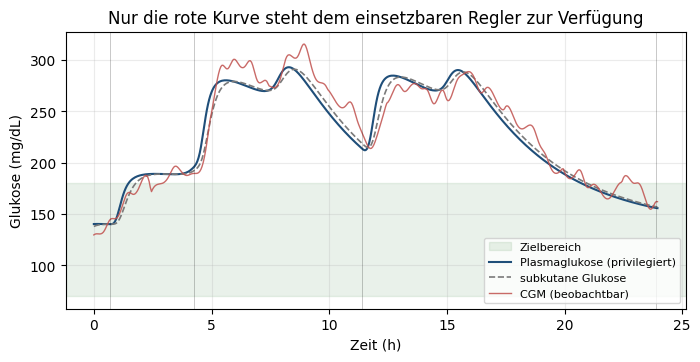

In [3]:
def einen_tag(seed):
    """Ein simulierter Tag unter konstanter Basalrate. Gibt die drei Kurven zurück."""
    env.reset(seed=seed)
    plasma, subq, cgm, meals = [], [], [], []
    done = False
    while not done:
        _, _, term, trunc, info = env.step_insulin(env.basal_ss)   # nur Basalrate
        plasma.append(env._core.patient.state[3] / env.Vg)
        subq.append(info["bg"]); cgm.append(info["cgm"]); meals.append(info["meal"])
        done = term or trunc
    return (np.array(plasma), np.array(subq), np.array(cgm), np.array(meals))

lags, sd_noise, mae = [], [], []
for seed in range(100000, 100020):
    plasma, subq, cgm, meals = einen_tag(seed)
    lags.append(max(range(11), key=lambda k: np.corrcoef(plasma[:len(plasma)-k], subq[k:])[0, 1]))
    sd_noise.append(np.std(cgm - subq))
    mae.append(np.mean(np.abs(cgm - plasma)))

stat = lambda v: f"{np.mean(v):.2f} +/- {np.std(v, ddof=1):.2f}"
print(f"Verzögerung subkutan gegen Plasma : {int(np.median(lags))} Schritte = "
      f"{int(np.median(lags))*3} min  (in {lags.count(int(np.median(lags)))} von {len(lags)} Episoden)")
print(f"Sensorrauschen (CGM - subkutan) SD : {stat(sd_noise)} mg/dL")
print(f"Mittlerer Betragsfehler CGM/Plasma : {stat(mae)} mg/dL")

plasma, subq, cgm, meals = einen_tag(100007)   # eine Episode zur Anschauung
t = np.arange(len(plasma)) * 3 / 60

fig, ax = plt.subplots()
ax.axhspan(70, 180, color="#2e7d32", alpha=0.10, label="Zielbereich")
ax.plot(t, plasma, label="Plasmaglukose (privilegiert)", color="#1f4e79")
ax.plot(t, subq, "--", lw=1.2, color="#7a7a7a", label="subkutane Glukose")
ax.plot(t, cgm, lw=1.0, color="#c0504d", alpha=0.85, label="CGM (beobachtbar)")
for m in t[np.array(meals) > 0]: ax.axvline(m, color="k", lw=0.5, alpha=0.3)
ax.set_xlabel("Zeit (h)"); ax.set_ylabel("Glukose (mg/dL)"); ax.legend(fontsize=8)
ax.set_title("Nur die rote Kurve steht dem einsetzbaren Regler zur Verfügung")
plt.show()

## 3. Die klinische Referenztherapie

Der Basal-Bolus-Regler ist die übliche Praxis: eine konstante Basalrate plus ein
Bolus zu jeder Mahlzeit, berechnet aus Kohlenhydratfaktor und Korrekturfaktor.
Wichtig für die Fragestellung: **dieser Regler bekommt die Mahlzeit
angekündigt.**

Bewertet wird nach dem internationalen Konsens
(Battelino et al. 2019, Diabetes Care 42(8):1593).

In [4]:
for name, (op, val) in TARGETS.items():
    print(f"  {name:<12} Ziel {op} {val} %")

  tir          Ziel > 70.0 %
  tbr_total    Ziel < 4.0 %
  tbr_level2   Ziel < 1.0 %
  tar_total    Ziel < 25.0 %
  tar_level2   Ziel < 5.0 %
  cv           Ziel < 36.0 %


In [5]:
from baselines import run_basal_bolus, run_constant_basal

# dieselben 20 Seeds wie runs/baselines/summary_adult001_heldout.json
seeds = list(range(100000, 100020))
env_b = T1DEnv(patient_name="adult#001", obs_mode="cgm", days=1)
for label, fn in (("konstante Basalrate", run_constant_basal), ("Basal-Bolus", run_basal_bolus)):
    rows = [fn(env_b, s) for s in seeds]
    agg = {k: float(np.mean([r[k] for r in rows])) for k in
           ("tir","tbr_total","tbr_level2","tar_total","tar_level2","cv","mean_bg","risk_index")}
    print(f"{label:>22}: {summarize(agg)}")

   konstante Basalrate: TIR 35.5% | TBR 0.0% (L2 0.00%) | TAR 64.5% (L2 18.6%) | CV 21.8% | mittl. BG 202 mg/dL | RI 12.87


           Basal-Bolus: TIR 90.9% | TBR 1.4% (L2 0.51%) | TAR 7.7% (L2 0.0%) | CV 22.9% | mittl. BG 134 mg/dL | RI 3.09


## 4. Der Aktionsraum, aus der Referenz hergeleitet

Die Verteilung der klinischen Insulinraten ist extrem schief: in 99 % der
Schritte exakt die Basalrate, im Maximum das 124-fache. Ein linearer Aktionsraum
verschwendet seine Auflösung dort, wo fast alle Entscheidungen liegen. Deshalb
ist die Aktion ein Exponent auf die patienteneigene Basalrate:

$$u = u_{basal} \cdot 160^{\,a}, \qquad a \in [-1, 1]$$

`a = 0` ist exakt die Basalrate des Patienten. Der Aktionsraum ist damit
patientennormiert und ohne Umskalierung auf jede Kohorte übertragbar.

In [6]:
for a in (-1.0, -0.5, 0.0, 0.5, 0.76, 0.897, 1.0):
    u = env.basal_ss * MAX_MULT ** a
    print(f"  a = {a:+.3f}  ->  {u:8.5f} U/min  = {u/env.basal_ss:7.2f} x Basalrate")
print("\nEin Mahlzeitenbolus liegt bei a = 0,76 bis 0,95.")

  a = -1.000  ->   0.00013 U/min  =    0.01 x Basalrate
  a = -0.500  ->   0.00167 U/min  =    0.08 x Basalrate
  a = +0.000  ->   0.02112 U/min  =    1.00 x Basalrate
  a = +0.500  ->   0.26718 U/min  =   12.65 x Basalrate
  a = +0.760  ->   0.99972 U/min  =   47.33 x Basalrate
  a = +0.897  ->   2.00375 U/min  =   94.86 x Basalrate
  a = +1.000  ->   3.37963 U/min  =  160.00 x Basalrate

Ein Mahlzeitenbolus liegt bei a = 0,76 bis 0,95.


## 5. Die beiden Beobachtungsräume

Identische Dynamik, identische Hyperparameter, identische Seeds. Der **einzige**
Unterschied ist, was der Agent sieht.

In [7]:
for mode in ("privileged", "cgm"):
    e = T1DEnv(patient_name="adult#001", obs_mode=mode, days=1)
    o, _ = e.reset(seed=100000)
    print(f"{mode:>11}: Beobachtungsdimension {o.shape[0]}")
print()
print("privileged: 13 ODE-Zustände, Plasmaglukose, CGM, Mahlzeit jetzt,")
print("            ANGEKUENDIGTE Mahlzeit, Insulinhistorie (12), Tageszeit (2)")
print("cgm       : CGM-Verlauf (12), Insulinhistorie (12), Tageszeit (2)")
print("            keine Ankündigung, kein wahrer Wert, kein Modellzustand")

 privileged: Beobachtungsdimension 31
        cgm: Beobachtungsdimension 26

privileged: 13 ODE-Zustände, Plasmaglukose, CGM, Mahlzeit jetzt,
            ANGEKUENDIGTE Mahlzeit, Insulinhistorie (12), Tageszeit (2)
cgm       : CGM-Verlauf (12), Insulinhistorie (12), Tageszeit (2)
            keine Ankündigung, kein wahrer Wert, kein Modellzustand


## 6. Ergebnisse: Information gegen Personalisierung

Der Versuch kreuzt zwei Achsen. Die erste ist die eigentliche Fragestellung:
was der Regler **sieht**. Die zweite ordnet ihre Größe ein: auf wen der Regler
**zugeschnitten** ist. Alle vier Zellen werden auf denselben zehn nie
trainierten Patienten und denselben Episoden-Seeds ausgewertet.

Jede Zelle wurde mit **zwei unabhängigen Zufallsstartwerten** trainiert. Das ist
keine nachträgliche Absicherung: die Streuung zwischen Startwerten erreicht in
einzelnen Zellen 5,0 Punkte und damit dieselbe Größenordnung wie der gesuchte
Personalisierungseffekt. Ausgewertet wird deshalb über beide Durchläufe.

In [8]:
import glob
def load(p):
    with open(p) as f: return json.load(f)

seedfiles = sorted(glob.glob("../runs/cohort_seed*/cohort_summary.json"))
per = [load(p)["arms"] for p in seedfiles]
tir = lambda arms, k: arms[k]["overall"]["tir"]
print(f"{len(per)} Trainingsdurchläufe, je 200 Held-out-Episoden pro Zelle "
      f"(10 Patienten x 20 Episoden)\n")

head = " ".join(f"{'Lauf '+str(i+1):>8}" for i in range(len(per)))
print(f"{'Zelle':>28} {head} {'Mittel':>8} {'Spanne':>7}")
for pers in ("generalist", "personalisiert"):
    for obs in ("privileged", "cgm"):
        k = f"{pers}_{obs}"
        v = [tir(a, k) for a in per]
        print(f"{k:>28} " + " ".join(f"{x:7.1f}%" for x in v)
              + f" {np.mean(v):7.1f}% {max(v)-min(v):7.1f}")

gap  = [tir(a, f"{p}_privileged") - tir(a, f"{p}_cgm")
        for p in ("generalist", "personalisiert") for a in per]
pgain = [tir(a, f"personalisiert_{o}") - tir(a, f"generalist_{o}")
         for o in ("privileged", "cgm") for a in per]
print()
for lab, v in (("Informationslücke", gap), ("Personalisierung", pgain)):
    einzel = ", ".join(f"{x:+.1f}" for x in sorted(v))
    print(f"  {lab:>18}: {np.mean(v):+6.1f} +/- {np.std(v, ddof=1):.1f} Punkte   "
          f"(alle vier Messungen: {einzel})")

2 Trainingsdurchläufe, je 200 Held-out-Episoden pro Zelle (10 Patienten x 20 Episoden)

                       Zelle   Lauf 1   Lauf 2   Mittel  Spanne
       generalist_privileged    71.0%    73.3%    72.1%     2.3
              generalist_cgm    42.4%    37.4%    39.9%     5.0
   personalisiert_privileged    74.8%    72.4%    73.6%     2.5
          personalisiert_cgm    36.7%    38.3%    37.5%     1.6

   Informationslücke:  +34.2 +/- 4.1 Punkte   (alle vier Messungen: +28.6, +34.1, +35.9, +38.1)
    Personalisierung:   -0.5 +/- 4.0 Punkte   (alle vier Messungen: -5.7, -0.9, +0.9, +3.9)


Die beiden Achsen verhalten sich völlig unterschiedlich. Der Beobachtungsraum
ist rund **34 Prozentpunkte** wert und liegt in keiner der vier Messungen auch
nur in der Nähe von null. Die Personalisierung ist mit **-0,5 +/- 4,0** Punkten
und wechselndem Vorzeichen von null nicht zu unterscheiden.

Ein früherer Stand dieser Auswertung meldete einen Personalisierungsgewinn von
+5,4 Punkten. Er war ein Artefakt: die Seed-Blöcke der Trainingsprozesse
reichten in den Auswertungsbereich, sodass die personalisierten Regler auf 19 der
20 Episoden trainiert hatten, auf denen sie gemessen wurden. Nach der Korrektur
verschwand der Effekt vollständig. Die kontaminierten Läufe liegen unverändert
unter `runs/_invalid_seedleak/`, die Trennung erzwingt jetzt eine
Zusicherung in `make_vec_env`.

In [9]:
# Aufschlüsselung nach Patientengruppe, gemittelt über beide Durchläufe
grp = {k: {g: float(np.mean([a[k]["by_group"][g]["tir"] for a in per]))
           for g in ("adolescent", "adult", "child")} for k in per[0]}
for key in ("personalisiert_privileged", "generalist_privileged",
            "personalisiert_cgm", "generalist_cgm"):
    line = "  ".join(f"{g[:5]} {grp[key][g]:5.1f}" for g in ("adolescent","adult","child"))
    tbr  = float(np.mean([a[key]["overall"]["tbr_total"] for a in per]))
    term = sum(a[key]["overall"]["n_terminated"] for a in per)
    n    = sum(a[key]["overall"]["n_episodes"] for a in per)
    print(f"{key:>26}: {line}   TBR {tbr:4.2f}%   Abbrüche {term}/{n}")

bl = load("../runs/baselines/summary_heldout_heldout.json")["controllers"]
print()
for c, lab in (("basal", "konstante Basalrate"), ("bb", "Basal-Bolus (klinisch)")):
    a = bl[c]
    bg = a["by_group"]
    line = "  ".join(f"{g[:5]} {bg[g]['tir']:5.1f}" for g in ("adolescent","adult","child"))
    print(f"{lab:>26}: {line}   TBR {a['tbr_total']:4.2f}%   "
          f"Abbrüche {a['n_terminated']}/{a['n_episodes']}")

 personalisiert_privileged: adole  75.5  adult  72.4  child  73.2   TBR 1.34%   Abbrüche 33/400
     generalist_privileged: adole  76.0  adult  68.5  child  72.0   TBR 1.38%   Abbrüche 21/400
        personalisiert_cgm: adole  36.3  adult  34.5  child  40.7   TBR 0.00%   Abbrüche 75/400
            generalist_cgm: adole  37.7  adult  36.9  child  43.8   TBR 0.00%   Abbrüche 66/400

       konstante Basalrate: adole  34.7  adult  33.3  child  40.5   TBR 0.00%   Abbrüche 37/200
    Basal-Bolus (klinisch): adole  88.1  adult  90.3  child  72.3   TBR 5.64%   Abbrüche 7/200


Zwei Einschränkungen gehören zum Ergebnis. Erstens schlägt auf der Kohorte
**keiner** der gelernten Regler die klinische Standardtherapie (73,6 % gegen
82,4 %); ein Vorversuch auf einem einzelnen, gut regelbaren Erwachsenen hatte
das Gegenteil ergeben. Zweitens erreicht die klinische Referenz ihre höhere
Time in Range um den Preis von 5,6 % Zeit unterhalb des Zielbereichs und
verfehlt damit die Sicherheitsziele, bei Kindern mit 11,73 % deutlich. Die
privilegierten Regler bleiben mit 0,4 bis 2,3 % TBR darunter, erreichen die
Konsensgrenze für schwere Hypoglykämie aber nicht in jedem Durchlauf.

Der Vergleich fällt also nicht eindeutig zugunsten einer Seite aus: die
klinische Therapie hat die höhere Time in Range, die gelernten Regler das
geringere Unterzuckerungsrisiko.

## 7. Sensitivitätsanalyse (Morris-Screening)

Methodisch dasselbe Verfahren wie im Vorlesungsbeispiel am Noble-Modell: SALib,
elementare Effekte, zehn Parameter. Zielgröße ist hier die Time in Range. Die
Frage lautet: **welche physiologischen Parameter bestimmen, wie gut sich ein
Patient überhaupt regeln lässt.**

In [10]:
cands = sorted(glob.glob("../runs/sensitivity/morris_*.json"))
if cands:
    sens = load(cands[-1])
    print(f"Regler {sens['controller']}, Variation +/- {int(sens['rel_range']*100)} %, "
          f"{sens['trajectories']} Trajektorien\n")
    print(f"{'Parameter':<8} {'mu*':>8} {'sigma':>8}   Bedeutung")
    for r in sens["results"]:
        print(f"{r['name']:<8} {r['mu_star']:8.2f} {r['sigma']:8.2f}   {r['description']}")
    print(f"\nTIR-Spanne über alle Parametersätze: "
          f"{sens['qoi_min']:.1f} bis {sens['qoi_max']:.1f} % (Median {sens['qoi_median']:.1f} %)")
else:
    print("Sensitivitätsanalyse noch nicht gelaufen: python3 src/sensitivity.py --controller bb")

Regler bb, Variation +/- 20 %, 12 Trajektorien

Parameter      mu*    sigma   Bedeutung
kp1         33.02    34.43   Basisrate der endogenen Glukoseproduktion
kp3         16.30    17.91   Insulinwirkung auf die Glukoseproduktion
Km0         14.00    14.99   Michaelis-Konstante der Glukoseaufnahme
Vmx          9.56     9.55   insulinabhaengige Glukoseaufnahme
kmax         7.01     3.51   maximale Magenentleerungsrate
kd           2.07     1.94   Dissoziation des subkutanen Insulins
ka1          0.78     0.80   Resorption des subkutanen Insulins
kabs         0.60     0.60   Resorptionsrate aus dem Darm
ksc          0.59     0.47   Diffusion Plasma zu subkutaner Glukose
u2ss         0.00     0.00   stationaerer Insulinbedarf

TIR-Spanne über alle Parametersätze: 47.0 bis 96.1 % (Median 75.4 %)


## 8. Fazit

Die Kernaussage lässt sich in einem Satz zusammenfassen: **der Unterschied
zwischen den beiden Agenten ist keine Frage der Rechenzeit oder der
Netzarchitektur, sondern der verfügbaren Information.** Ein Mahlzeitenbolus muss
dem Glukoseanstieg vorausgehen; zum Entscheidungszeitpunkt ist im CGM-Verlauf
noch nichts davon zu sehen, und der Sensor hinkt zusätzlich um zwölf Minuten
hinterher.

In Zahlen: die Informationslücke beträgt 34,2 +/- 4,1 Prozentpunkte Time in
Range, die Personalisierung -0,5 +/- 4,0. Dass ausgerechnet ksc, die
Diffusionskonstante der Sensorverzögerung, im Morris-Screening mit mu* = 0,59
kaum wirkt, schärft die Deutung: nicht die Trägheit des Sensors ist der
Engpass, sondern die fehlende Mahlzeitenankündigung.

Die ausführliche Diskussion steht in der Projektarbeit.